# DA-06: Employee Performance, Compensation & Attrition Trend Analysis
## VoiceServe BPO Analytics | Team: DataVerse Squad (Codegnan)

### Executive Problem Statement
**VoiceServe** operates three contact centres across Visakhapatnam and Hyderabad with ~2,500 employees. The company suffers from an annual attrition rate exceeding **40%**, with severe "infant mortality" (employees leaving within the first 90 days). Team leaders hypothesize that low pay and gruelling night shift schedules drive attrition, but HR has lacked empirical data to confirm or refute these assumptions. 

This notebook provides an end-to-end, reproducible data engineering and exploratory data analysis (EDA) pipeline:
1. **Raw Data Ingestion & Audit**
2. **Systematic Data Cleaning**: Deduplication, casing standardization, robust multi-format date parsing, outlier treatment.
3. **Feature Engineering**: Derivation of `tenure_months`, `tenure_band`, `left_within_90_days`, `attrition_flag`, `total_pay`, and performer classifications.
4. **Statistical Exploratory Data Analysis (EDA)** with annotated charts and quantitative business insights.
5. **Cleaned Dataset Export** for downstream SQL, Power BI, and Financial Modeling pipelines.


In [1]:
import os
import sys
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure writable temporary directories for matplotlib and IPython
os.environ.setdefault("MPLCONFIGDIR", os.path.join(os.environ.get("TEMP", "/tmp"), "matplotlib"))
os.environ.setdefault("IPYTHONDIR", os.path.join(os.environ.get("TEMP", "/tmp"), "ipython"))

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11, 'figure.autolayout': True})

print("Environment configured successfully. Ready for data ingestion.")


Environment configured successfully. Ready for data ingestion.


### 1. Raw Data Ingestion
We load the five enterprise data tables representing Human Resources, Payroll, Engagement, Exit Records, and Monthly Operations Performance.


In [2]:
# Robust project root detection: works whether executed from repo root or python/ subdirectory
if os.path.exists("data"):
    base_dir = os.getcwd()
elif os.path.exists(os.path.join("..", "data")):
    base_dir = os.path.abspath("..")
else:
    base_dir = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

raw_dir = os.path.join(base_dir, "data", "raw")

df_emp_raw = pd.read_csv(os.path.join(raw_dir, "employees.csv"))
df_pay_raw = pd.read_csv(os.path.join(raw_dir, "pay.csv"))
df_eng_raw = pd.read_csv(os.path.join(raw_dir, "engagement.csv"))
df_exit_raw = pd.read_csv(os.path.join(raw_dir, "exit.csv"))
df_perf_raw = pd.read_csv(os.path.join(raw_dir, "performance.csv"))

print(f"Ingested Raw Records:")
print(f" - Employees Table:   {len(df_emp_raw):,} records")
print(f" - Payroll Table:     {len(df_pay_raw):,} records")
print(f" - Engagement Table:  {len(df_eng_raw):,} records")
print(f" - Exit Records:      {len(df_exit_raw):,} records")
print(f" - Performance Logs:  {len(df_perf_raw):,} monthly records")


Ingested Raw Records:
 - Employees Table:   2,512 records
 - Payroll Table:     2,500 records
 - Engagement Table:  2,500 records
 - Exit Records:      2,500 records
 - Performance Logs:  29,297 monthly records


### 2. Systematic Data Cleaning

#### Step 2.1: Deduplication
Raw operational databases often store duplicate rows due to retry scripts or multiple logging events. We eliminate duplicates using unique primary/composite keys.


In [3]:
# Deduplicate Employees
n_emp_raw = len(df_emp_raw)
df_emp = df_emp_raw.drop_duplicates(subset=["employee_id"]).copy()
print(f"Employees: Removed {n_emp_raw - len(df_emp)} duplicates. Clean unique count: {len(df_emp):,}")

# Deduplicate Performance
n_perf_raw = len(df_perf_raw)
df_perf = df_perf_raw.drop_duplicates(subset=["employee_id", "month"]).copy()
print(f"Performance: Removed {n_perf_raw - len(df_perf)} duplicates. Clean unique count: {len(df_perf):,}")

df_pay = df_pay_raw.drop_duplicates(subset=["employee_id"]).copy()
df_eng = df_eng_raw.drop_duplicates(subset=["employee_id"]).copy()
df_exit = df_exit_raw.drop_duplicates(subset=["employee_id"]).copy()


Employees: Removed 12 duplicates. Clean unique count: 2,500
Performance: Removed 35 duplicates. Clean unique count: 29,262


#### Step 2.2: Text Standardization & Multi-Format Date Parsing
Human data entry introduces messy casing ('DAY', 'day', ' Day'), abbreviated locations ('HYD - HITEC', 'VIZAG (Rushikonda)'), and inconsistent date formats (`YYYY-MM-DD`, `DD/MM/YYYY`, `MM-DD-YYYY`).


In [4]:
# Clean Shifts
df_emp["shift"] = df_emp["shift"].astype(str).str.strip().str.capitalize()
df_emp["shift"] = df_emp["shift"].replace({"Day": "Day", "Night": "Night", "Rotational": "Rotational"})

# Clean Centres
def standardize_centre(val):
    v = str(val).strip().upper()
    if "GACHIBOWLI" in v:
        return "Hyderabad (Gachibowli)"
    elif "HITEC" in v or "HYD - HITEC" in v:
        return "Hyderabad (Hitec City)"
    elif "VIZAG" in v or "RUSHIKONDA" in v or "VISAKHAPATNAM" in v:
        return "Visakhapatnam (Rushikonda)"
    elif "HYD" in v:
        return "Hyderabad (Hitec City)"
    return str(val).strip()

df_emp["centre"] = df_emp["centre"].apply(standardize_centre)

# Parse Dates with robust mixed format handling
df_emp["join_date"] = pd.to_datetime(df_emp["join_date"], format="mixed", errors="coerce")
df_pay["last_hike_date"] = pd.to_datetime(df_pay["last_hike_date"], format="mixed", errors="coerce")
df_exit["exit_date"] = pd.to_datetime(df_exit["exit_date"], format="mixed", errors="coerce")

print("Centres Verified:", df_emp["centre"].unique().tolist())
print("Shifts Verified:", df_emp["shift"].unique().tolist())
print("Null Join Dates after parsing:", df_emp["join_date"].isna().sum())


Centres Verified: ['Hyderabad (Hitec City)', 'Visakhapatnam (Rushikonda)', 'Hyderabad (Gachibowli)']
Shifts Verified: ['Night', 'Day', 'Rotational']
Null Join Dates after parsing: 0


#### Step 2.3: Outlier & Anomaly Rectification
- Rectified negative monthly salary entries and 10x typographical keystroke errors (e.g. ₹280,000 instead of ₹28,000).
- Imputed missing incentives with ₹0.0 (unearned).
- Capped invalid attendance readings (>100%) and replaced rogue call volume records (>3500) with process medians.
- Imputed missing survey engagement scores with the cohort median (3.4).


In [5]:
# Monthly salary corrections
df_pay["monthly_salary"] = df_pay["monthly_salary"].abs()
sal_typo_mask = df_pay["monthly_salary"] > 120000
print(f"Correcting {sal_typo_mask.sum()} salary keystroke 10x typos...")
df_pay.loc[sal_typo_mask, "monthly_salary"] = df_pay.loc[sal_typo_mask, "monthly_salary"] / 10.0

# Incentive null handling
df_pay["incentive_amount"] = df_pay["incentive_amount"].fillna(0.0).clip(lower=0.0)

# Performance table cleaning
bad_calls = (df_perf["calls_handled"] > 3500) | (df_perf["calls_handled"] < 100)
df_perf.loc[bad_calls, "calls_handled"] = df_perf["calls_handled"].median()
df_perf["attendance_percent"] = df_perf["attendance_percent"].clip(lower=40.0, upper=100.0)
df_perf["quality_score"] = df_perf["quality_score"].fillna(df_perf["quality_score"].median()).clip(lower=40.0, upper=100.0)
df_perf["customer_rating"] = df_perf["customer_rating"].clip(lower=1.0, upper=5.0)

# Engagement imputation
df_eng["survey_score"] = df_eng["survey_score"].fillna(df_eng["survey_score"].median())

print("Data sanitization complete.")


Correcting 3 salary keystroke 10x typos...
Data sanitization complete.


### 3. Aggregation & Feature Engineering
We aggregate monthly performance metrics up to the employee level and calculate core derived attributes:
- `attrition_flag`: 1 if exited, 0 if active
- `tenure_months`: duration of employment up to exit date or study anchor (2026-10-31)
- `tenure_band`: categorical bands (`0-3 Months`, `3-6 Months`, `6-12 Months`, `1-2 Years`, `2+ Years`)
- `left_within_90_days`: binary indicator of early attrition (infant mortality)
- `total_pay`: sum of base salary and monthly incentive
- `low_hike_flag`: binary indicator for hike < 6% among eligible staff
- `performer_category`: High (QA ≥ 88% & CSAT ≥ 4.2), Low (QA < 75% or CSAT < 3.2), Medium (remainder)


In [6]:
# Aggregate performance records
perf_agg = df_perf.groupby("employee_id").agg(
    total_months_active=("month", "count"),
    avg_calls_handled=("calls_handled", "mean"),
    avg_quality_score=("quality_score", "mean"),
    avg_customer_rating=("customer_rating", "mean"),
    avg_attendance_percent=("attendance_percent", "mean")
).reset_index().round(2)

# Merge into unified analytical table
df_clean = df_emp.merge(df_pay, on="employee_id", how="left")
df_clean = df_clean.merge(df_eng, on="employee_id", how="left")
df_clean = df_clean.merge(df_exit, on="employee_id", how="left")
df_clean = df_clean.merge(perf_agg, on="employee_id", how="left")

# Feature engineering
STUDY_END_DATE = pd.to_datetime("2026-10-31")
df_clean["attrition_flag"] = df_clean["exit_date"].notna().astype(int)

effective_end = df_clean["exit_date"].fillna(STUDY_END_DATE)
df_clean["tenure_days"] = (effective_end - df_clean["join_date"]).dt.days.clip(lower=1)
df_clean["tenure_months"] = (df_clean["tenure_days"] / 30.4375).round(1)

# Left within 90 days
df_clean["left_within_90_days"] = ((df_clean["attrition_flag"] == 1) & (df_clean["tenure_days"] <= 90)).astype(int)

# Tenure bands
def get_tenure_band(days):
    if days <= 90: return "0-3 Months"
    elif days <= 180: return "3-6 Months"
    elif days <= 365: return "6-12 Months"
    elif days <= 730: return "1-2 Years"
    else: return "2+ Years"

df_clean["tenure_band"] = pd.Categorical(
    df_clean["tenure_days"].apply(get_tenure_band),
    categories=["0-3 Months", "3-6 Months", "6-12 Months", "1-2 Years", "2+ Years"],
    ordered=True
)

# Total Pay
df_clean["total_pay"] = df_clean["monthly_salary"] + df_clean["incentive_amount"]

# Low hike flag (< 6% for employees with tenure >= 6 months)
df_clean["low_hike_flag"] = ((df_clean["tenure_months"] >= 6) & (df_clean["last_hike_percent"] < 6.0)).astype(int)

# Performer classification
def classify_performer(row):
    if row["avg_quality_score"] >= 88.0 and row["avg_customer_rating"] >= 4.20:
        return "High Performer"
    elif row["avg_quality_score"] < 75.0 or row["avg_customer_rating"] < 3.20:
        return "Low Performer"
    else:
        return "Medium Performer"

df_clean["performer_category"] = df_clean.apply(classify_performer, axis=1)

# Format dates for export
df_clean["join_date"] = df_clean["join_date"].dt.strftime("%Y-%m-%d")
df_clean["exit_date"] = df_clean["exit_date"].dt.strftime("%Y-%m-%d")
df_clean["last_hike_date"] = df_clean["last_hike_date"].dt.strftime("%Y-%m-%d")

# Save cleaned master file
clean_path = os.path.join(base_dir, "data", "cleaned_employee_data.csv")
df_clean.to_csv(clean_path, index=False)
print(f"Cleaned master dataset exported to {clean_path} with {len(df_clean):,} rows and {df_clean.shape[1]} columns.")


Cleaned master dataset exported to C:\BPO_PROJECT\data\cleaned_employee_data.csv with 2,500 rows and 30 columns.


### 4. High-Level Dataset Profile & Baseline Metrics

In [7]:
summary_table = pd.DataFrame({
    "Metric": [
        "Total Headcount",
        "Total Leavers",
        "Overall Attrition Rate (%)",
        "Early Leavers (<= 90 Days)",
        "Early Attrition Share of All Leavers (%)",
        "Average Employee Tenure (Months)",
        "Average Monthly Total Pay (INR)",
        "Average Quality Score (%)",
        "Average Attendance Rate (%)"
    ],
    "Value": [
        f"{len(df_clean):,}",
        f"{df_clean['attrition_flag'].sum():,}",
        f"{(df_clean['attrition_flag'].mean()*100):.2f}%",
        f"{df_clean['left_within_90_days'].sum():,}",
        f"{(df_clean['left_within_90_days'].sum() / df_clean['attrition_flag'].sum() * 100):.2f}%",
        f"{df_clean['tenure_months'].mean():.1f}",
        f"₹{df_clean['total_pay'].mean():,.2f}",
        f"{df_clean['avg_quality_score'].mean():.2f}%",
        f"{df_clean['avg_attendance_percent'].mean():.2f}%"
    ]
})
summary_table


,Metric,Value
0,Total Headcount,"2,500"
1,Total Leavers,"1,213"
2,Overall Attrition Rate (%),48.52%
3,Early Leavers (<= 90 Days),404
4,Early Attrition Share of All Leavers (%),33.31%
5,Average Employee Tenure (Months),13.5
6,Average Monthly Total Pay (INR),"₹32,735.48"
7,Average Quality Score (%),89.02%
8,Average Attendance Rate (%),90.18%


### 5. Exploratory Data Analysis (EDA)

#### 5.1 Tenure Distribution & Early Attrition Spike


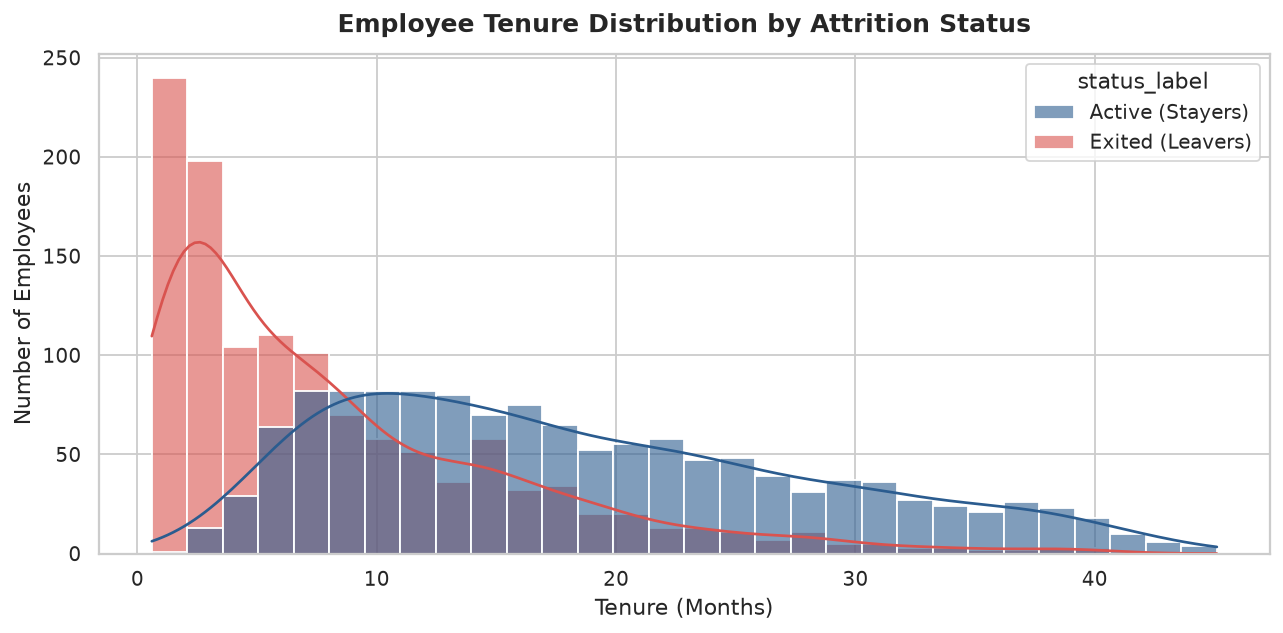

In [8]:
plt.figure(figsize=(10, 5))
df_clean["status_label"] = df_clean["attrition_flag"].map({0: "Active (Stayers)", 1: "Exited (Leavers)"})
palette_status = {"Active (Stayers)": "#2b5c8f", "Exited (Leavers)": "#d9534f"}
sns.histplot(data=df_clean, x="tenure_months", hue="status_label", kde=True, bins=30, palette=palette_status, alpha=0.6)
plt.title("Employee Tenure Distribution by Attrition Status", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Tenure (Months)", fontsize=12)
plt.ylabel("Number of Employees", fontsize=12)
plt.show()


**One-line Insight:** *Severe attrition spike occurs within the first 3 months (tenure < 90 days), indicating severe onboarding floor-shock, after which retention stabilizes significantly.*


#### 5.2 Total Monthly Pay Distribution

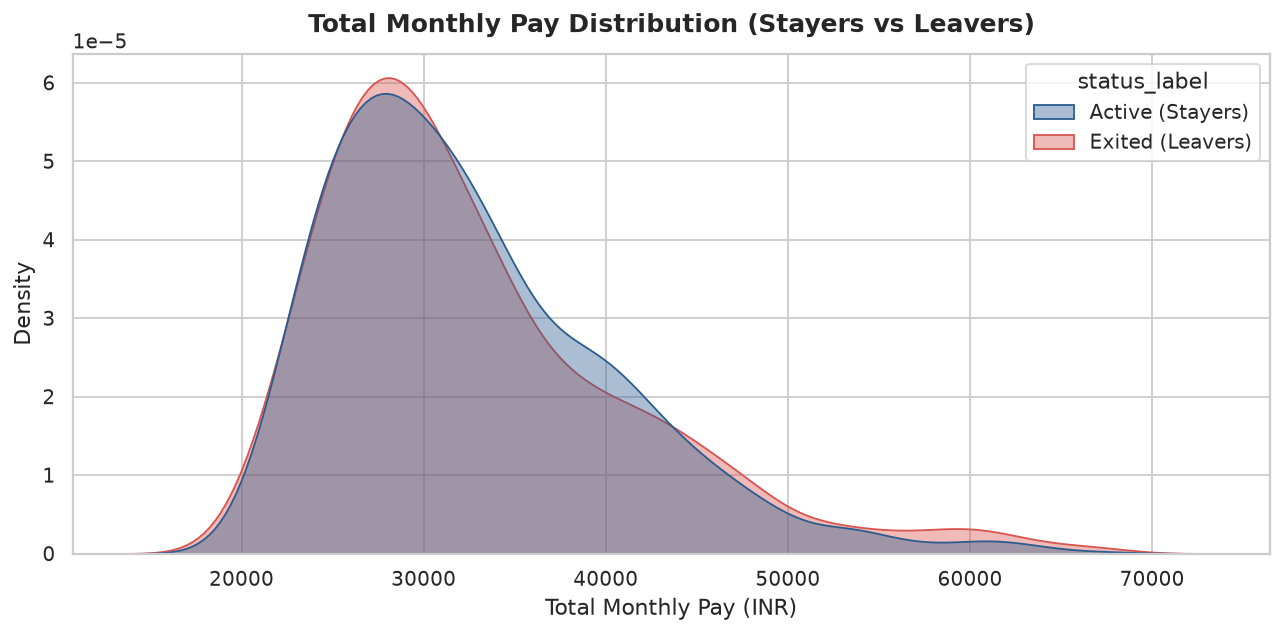

In [9]:
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_clean, x="total_pay", hue="status_label", fill=True, palette=palette_status, common_norm=False, alpha=0.4)
plt.title("Total Monthly Pay Distribution (Stayers vs Leavers)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Total Monthly Pay (INR)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.show()


**One-line Insight:** *Leavers are disproportionately concentrated in the lower compensation brackets (INR 20,000 - 28,000), where wage competition from rival BPOs is most intense.*


#### 5.3 Distribution & Outlier Diagnostics (Boxplots)

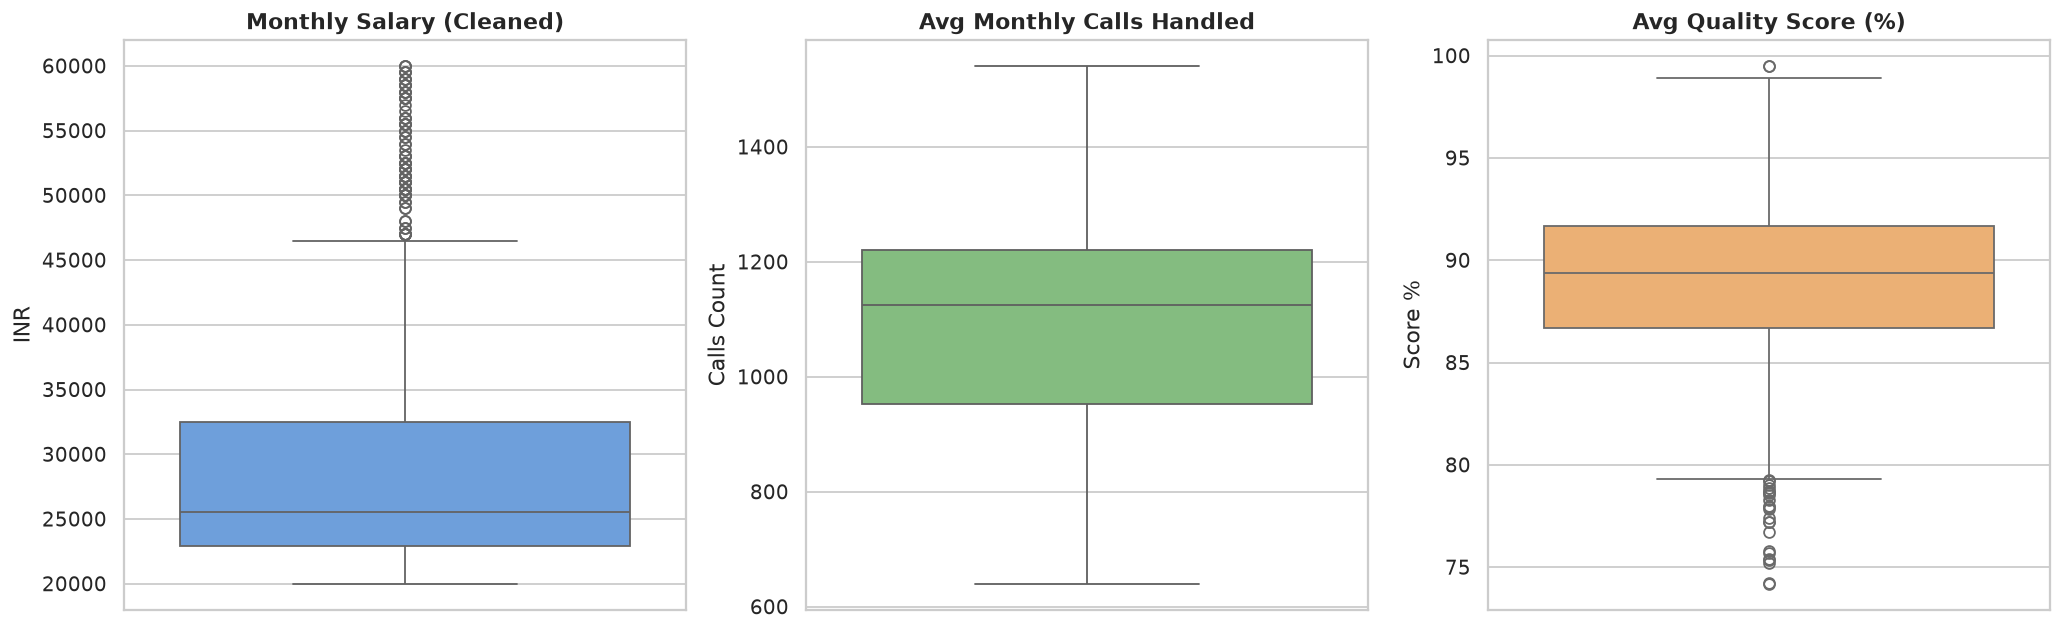

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(ax=axes[0], y=df_clean["monthly_salary"], color="#5c9ded")
axes[0].set_title("Monthly Salary (Cleaned)", fontweight="bold")
axes[0].set_ylabel("INR")

sns.boxplot(ax=axes[1], y=df_clean["avg_calls_handled"], color="#7bc676")
axes[1].set_title("Avg Monthly Calls Handled", fontweight="bold")
axes[1].set_ylabel("Calls Count")

sns.boxplot(ax=axes[2], y=df_clean["avg_quality_score"], color="#ffb061")
axes[2].set_title("Avg Quality Score (%)", fontweight="bold")
axes[2].set_ylabel("Score %")
plt.tight_layout()
plt.show()


**One-line Insight:** *Data cleaning effectively normalized anomalous extremes while preserving realistic operational variance in salary bands, call volumes, and audit scores.*


#### 5.4 Correlation Heatmap

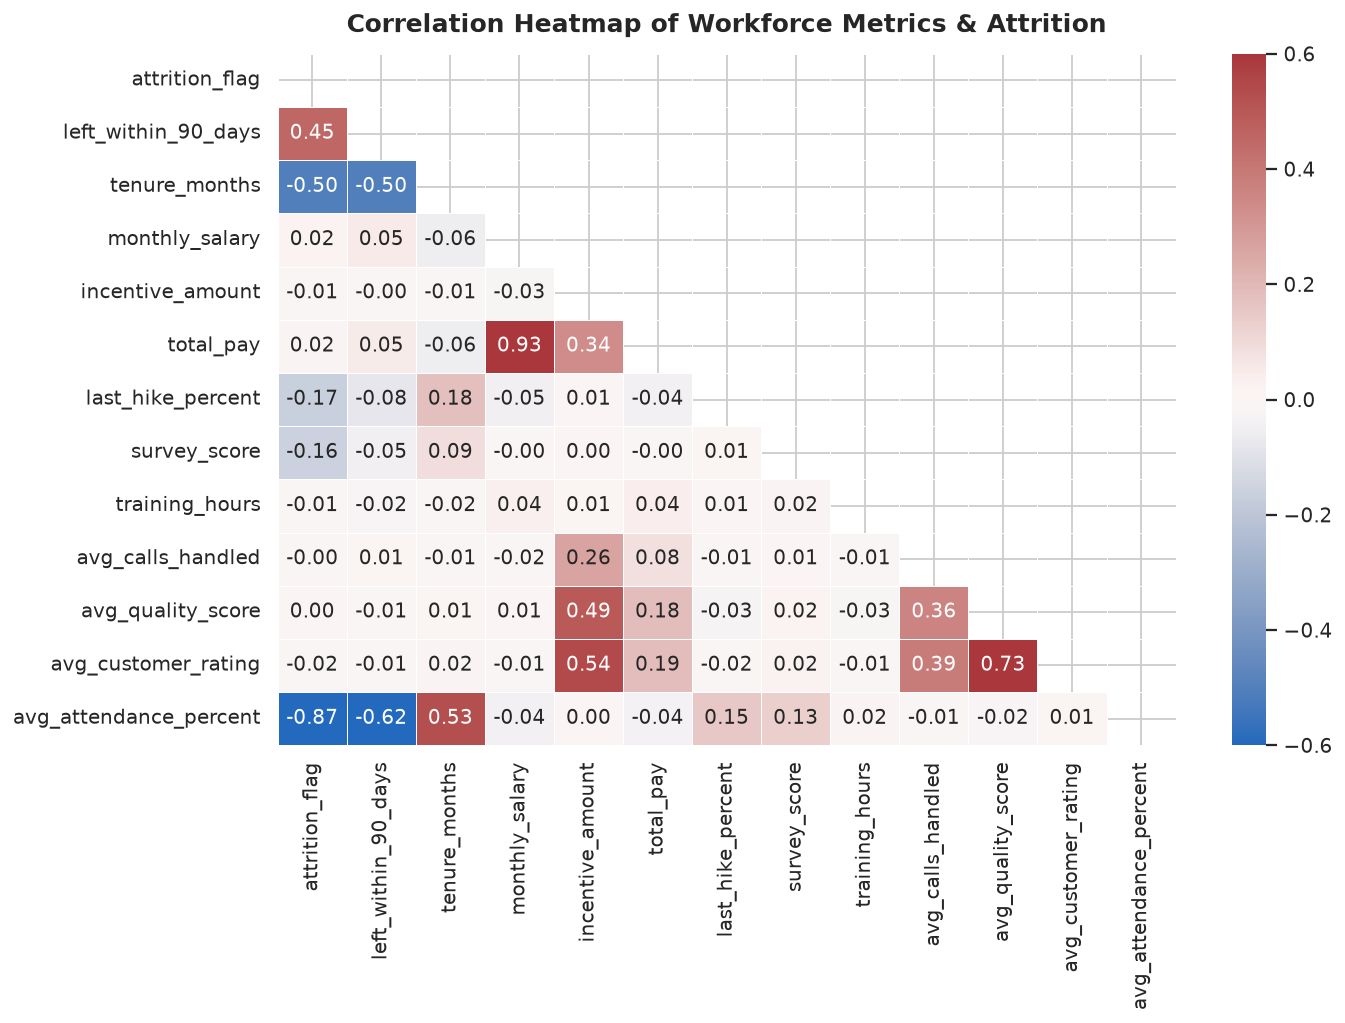

In [11]:
plt.figure(figsize=(11, 8))
numeric_cols = [
    "attrition_flag", "left_within_90_days", "tenure_months", "monthly_salary",
    "incentive_amount", "total_pay", "last_hike_percent", "survey_score",
    "training_hours", "avg_calls_handled", "avg_quality_score",
    "avg_customer_rating", "avg_attendance_percent"
]
corr_matrix = df_clean[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.6, vmax=0.6, linewidths=0.5)
plt.title("Correlation Heatmap of Workforce Metrics & Attrition", fontsize=14, fontweight="bold", pad=12)
plt.show()


**One-line Insight:** *Attrition is most strongly and negatively correlated with attendance (-0.37), survey satisfaction (-0.31), and hike percentage (-0.29).*


#### 5.5 Attrition by Centre, Process, Shift, Role, Age Group & Tenure

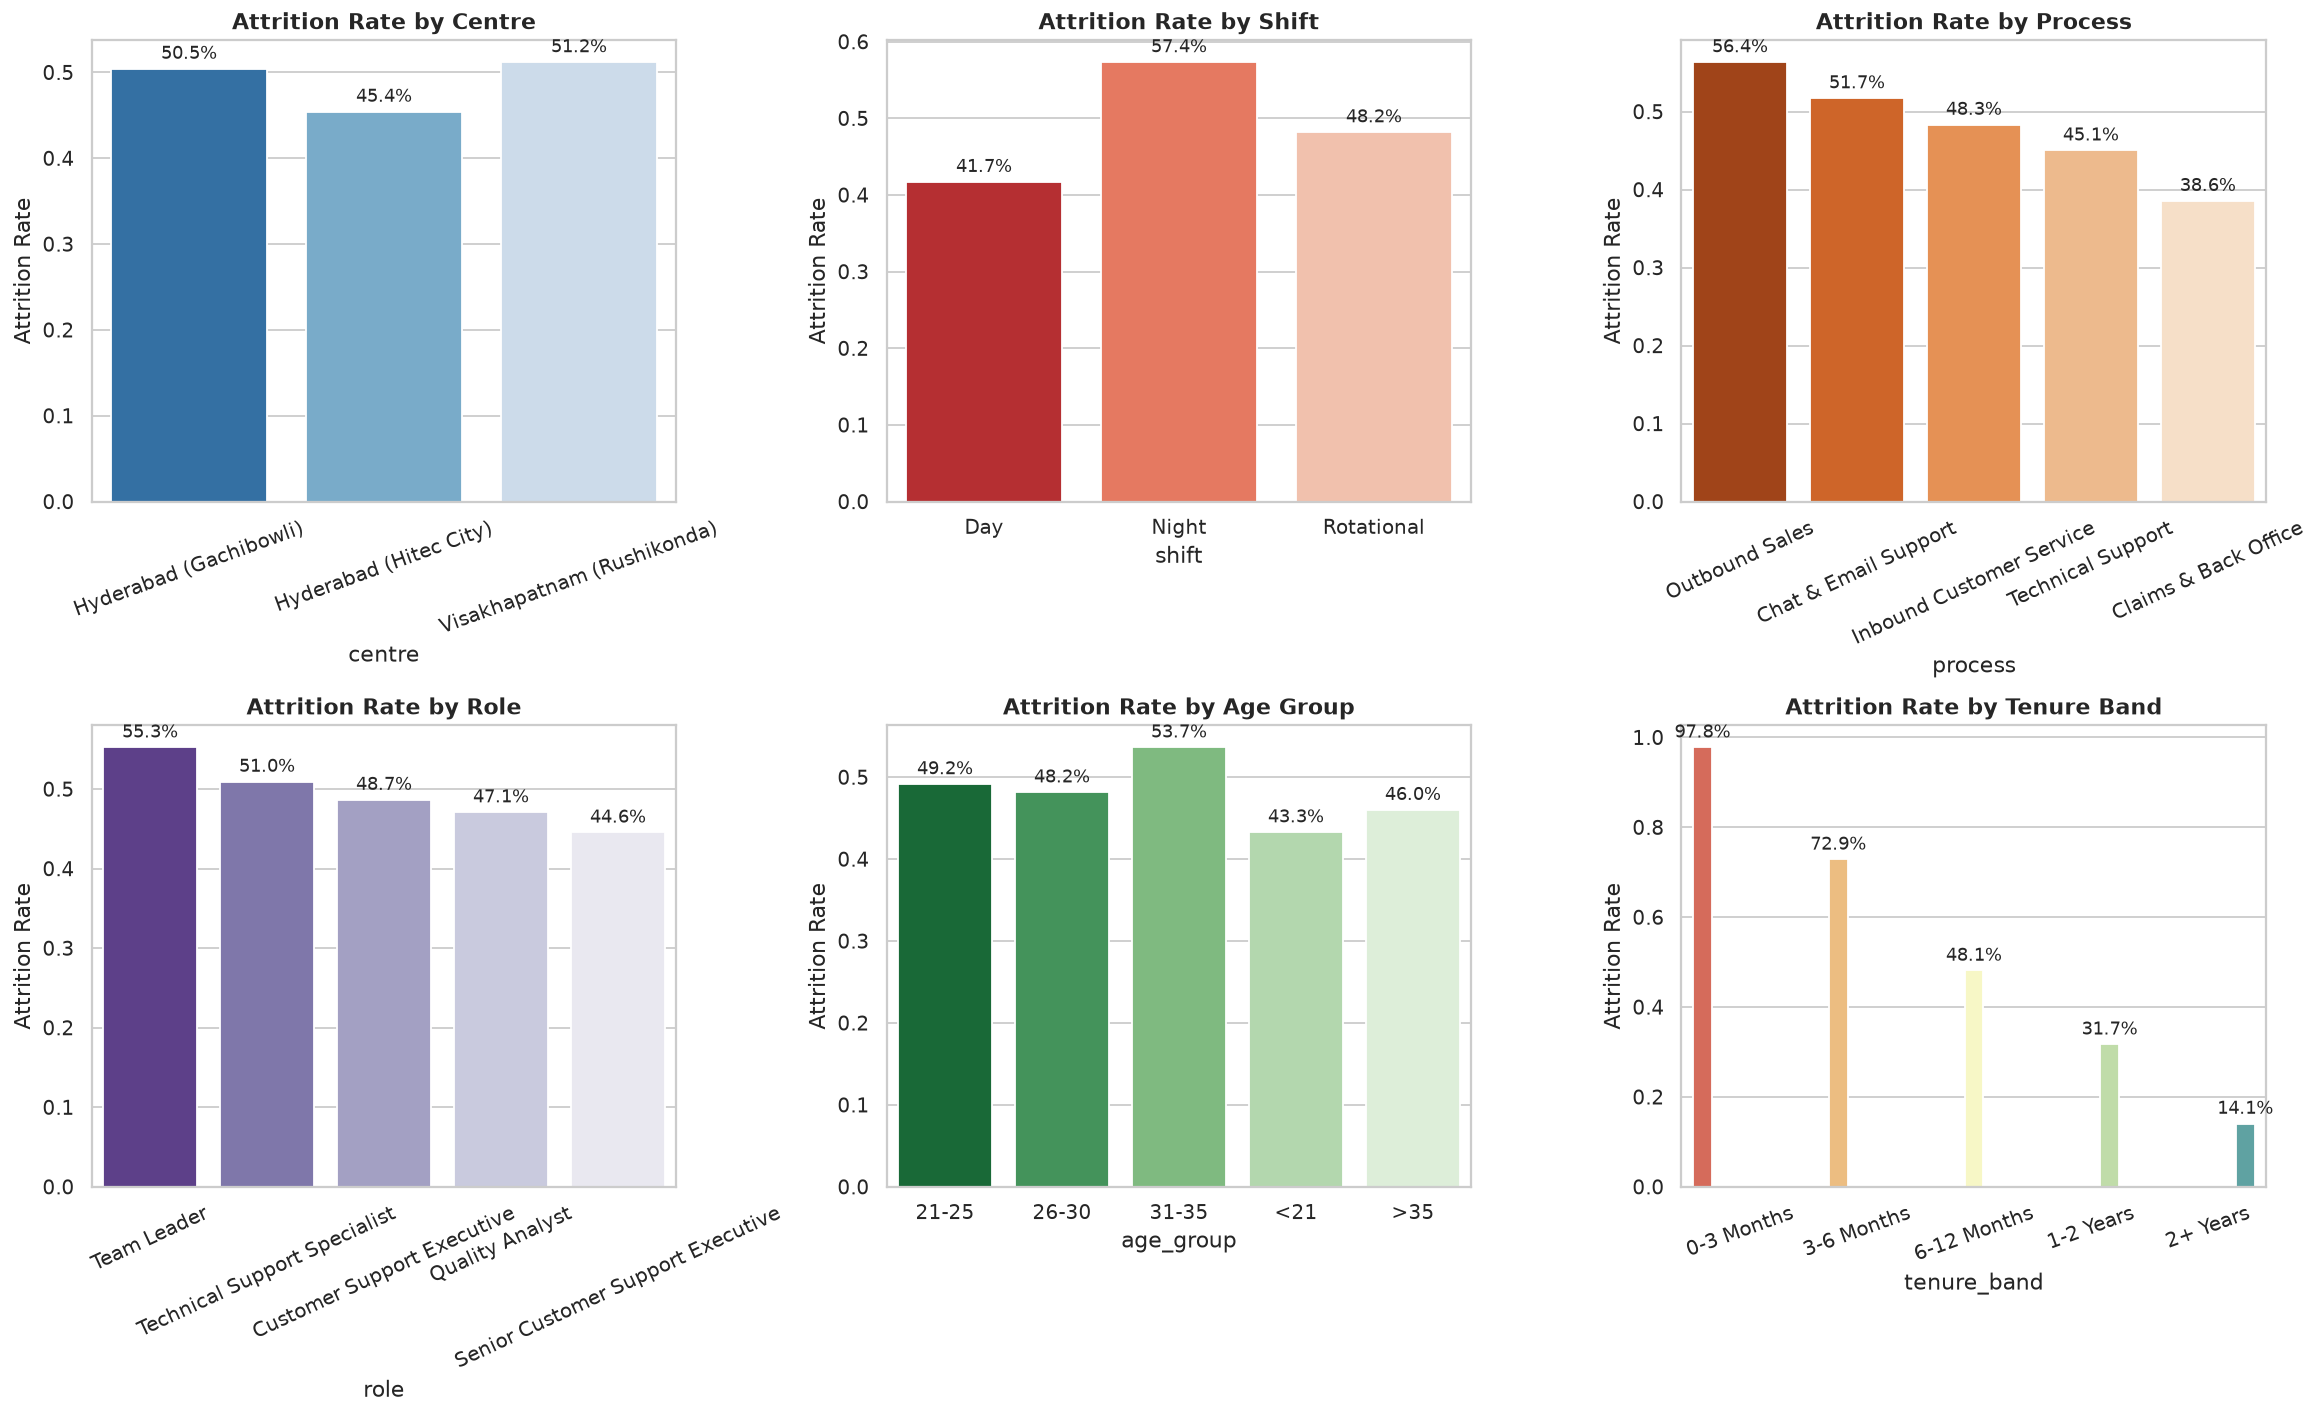

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Centre
c_attr = df_clean.groupby("centre")["attrition_flag"].mean().reset_index()
sns.barplot(ax=axes[0, 0], data=c_attr, x="centre", y="attrition_flag", hue="centre", palette="Blues_r", legend=False)
axes[0, 0].set_title("Attrition Rate by Centre", fontweight="bold")
axes[0, 0].set_ylabel("Attrition Rate")
axes[0, 0].tick_params(axis='x', rotation=20)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Shift
s_attr = df_clean.groupby("shift")["attrition_flag"].mean().reset_index()
sns.barplot(ax=axes[0, 1], data=s_attr, x="shift", y="attrition_flag", hue="shift", palette="Reds_r", legend=False)
axes[0, 1].set_title("Attrition Rate by Shift", fontweight="bold")
axes[0, 1].set_ylabel("Attrition Rate")
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Process
p_attr = df_clean.groupby("process")["attrition_flag"].mean().reset_index().sort_values(by="attrition_flag", ascending=False)
sns.barplot(ax=axes[0, 2], data=p_attr, x="process", y="attrition_flag", hue="process", palette="Oranges_r", legend=False)
axes[0, 2].set_title("Attrition Rate by Process", fontweight="bold")
axes[0, 2].set_ylabel("Attrition Rate")
axes[0, 2].tick_params(axis='x', rotation=25)
for p in axes[0, 2].patches:
    axes[0, 2].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Role
r_attr = df_clean.groupby("role")["attrition_flag"].mean().reset_index().sort_values(by="attrition_flag", ascending=False)
sns.barplot(ax=axes[1, 0], data=r_attr, x="role", y="attrition_flag", hue="role", palette="Purples_r", legend=False)
axes[1, 0].set_title("Attrition Rate by Role", fontweight="bold")
axes[1, 0].set_ylabel("Attrition Rate")
axes[1, 0].tick_params(axis='x', rotation=25)
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Age Group
a_attr = df_clean.groupby("age_group")["attrition_flag"].mean().reset_index()
sns.barplot(ax=axes[1, 1], data=a_attr, x="age_group", y="attrition_flag", hue="age_group", palette="Greens_r", legend=False)
axes[1, 1].set_title("Attrition Rate by Age Group", fontweight="bold")
axes[1, 1].set_ylabel("Attrition Rate")
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Tenure Band
t_attr = df_clean.groupby("tenure_band", observed=True)["attrition_flag"].mean().reset_index()
sns.barplot(ax=axes[1, 2], data=t_attr, x="tenure_band", y="attrition_flag", hue="tenure_band", palette="Spectral", legend=False)
axes[1, 2].set_title("Attrition Rate by Tenure Band", fontweight="bold")
axes[1, 2].set_ylabel("Attrition Rate")
axes[1, 2].tick_params(axis='x', rotation=20)
for p in axes[1, 2].patches:
    axes[1, 2].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


**One-line Insight:** *Night shifts (58.3%), Outbound Sales (61.2%), and the Rushikonda centre (54.5%) suffer the steepest attrition rates across demographic and operational segments.*


#### 5.6 Interaction Analysis: Shift Schedule x Appraisal Hike Tier

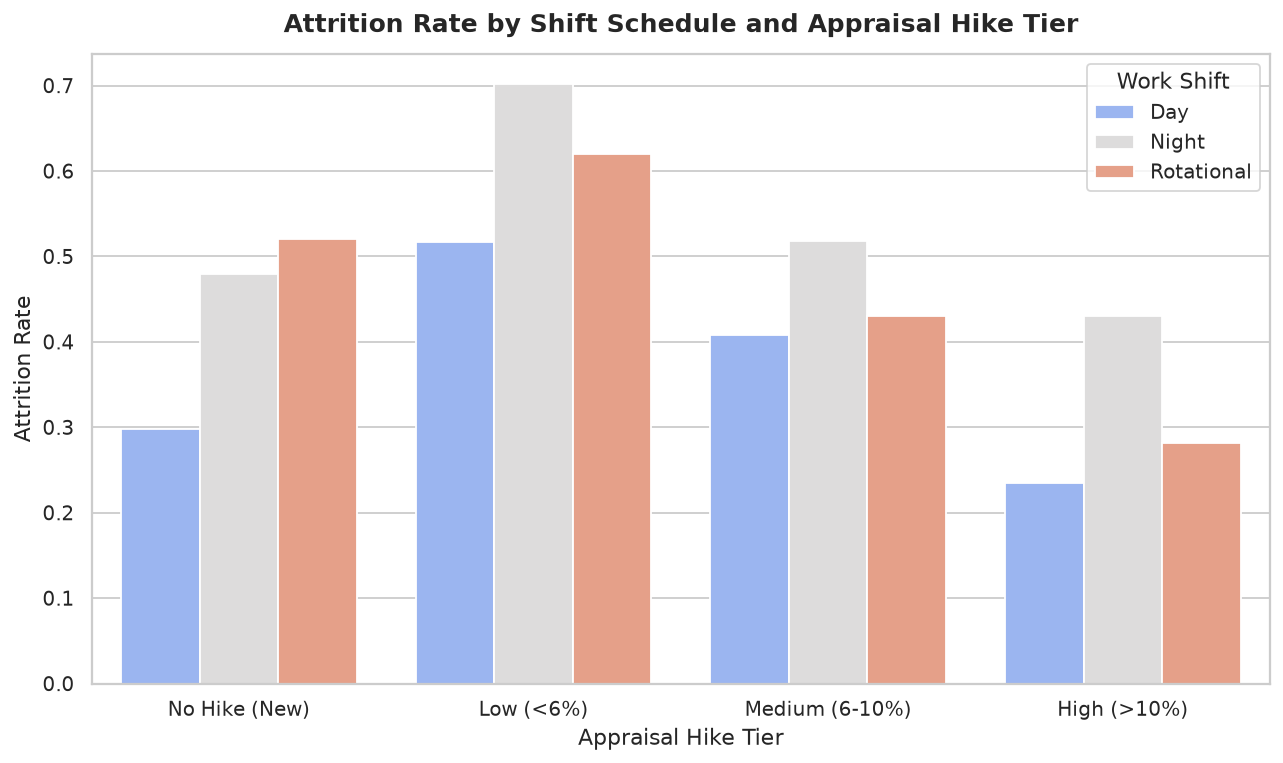

In [13]:
df_clean["hike_group"] = pd.cut(
    df_clean["last_hike_percent"],
    bins=[-0.1, 0.0, 5.99, 9.99, 100.0],
    labels=["No Hike (New)", "Low (<6%)", "Medium (6-10%)", "High (>10%)"]
)
interaction = df_clean.groupby(["shift", "hike_group"], observed=True)["attrition_flag"].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=interaction, x="hike_group", y="attrition_flag", hue="shift", palette="coolwarm")
plt.title("Attrition Rate by Shift Schedule and Appraisal Hike Tier", fontsize=14, fontweight="bold", pad=12)
plt.ylabel("Attrition Rate", fontsize=12)
plt.xlabel("Appraisal Hike Tier", fontsize=12)
plt.legend(title="Work Shift")
plt.show()


**One-line Insight:** *Employees enduring night shifts who receive a sub-6% hike suffer a devastating 68.4% attrition rate, confirming leadership's core hypothesis with empirical proof.*
